# Multi-Modal Tree Ensembles for Survival Prediction (Calibrated Architecture)

### Key Improvements Applied:
1. **Correction of Treatment Imputation Paradox**:
   Patients with unrecorded radiation data survived 57.7 weeks on average (identical to recorded patients at 57.4 weeks). Forcing unrecorded doses to `0.0 Gy` previously destroyed the predictive power of radiation dose. We now preserve natural missingness with an indicator flag and let the imputer/HistGBM handle missing values without distortion.
2. **Duan's Smearing Retransformation Correction**:
   In tree regression trained on $\log(1 + y)$, naive $\exp(\hat{y}) - 1$ estimates the geometric mean / median, causing a ~20 week systematic underprediction gap. We calculate Duan's smearing factor ($s = \frac{1}{n}\sum \exp(e_i)$) on training residuals to align the predicted mean with actual survival.
3. **Robust Loss against Outliers**:
   HistGradientBoosting uses `loss="absolute_error"` so that extreme right-tail survival outliers (e.g., 228 weeks) do not distort predictions for the rest of the cohort.
4. **Holdout Test Set**:
   15% independent cohort saved to disk (`test_dataset_holdout.csv`) prior to training.

## 1. Environment & Imports

In [15]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
print("Libraries successfully imported.")

Libraries successfully imported.


## 2. Load Datasets

In [16]:
clinical = pd.read_csv("data/CFB-GBM_clinical_data_v03_20260619.tsv", sep="\t")
treatment = pd.read_csv("data/CFB-GBM_treatment_data_v02_20260129.tsv", sep="\t")
rano = pd.read_csv("data/CFB-GBM_rano_criteria_v04_20260909.tsv", sep="\t")
features = pd.read_csv("data/CFB_GBM_features_extraction_pyradiomics_v03_20260619.tsv", sep="\t")

print(f"Loaded Clinical:  {clinical.shape}")
print(f"Loaded Treatment: {treatment.shape}")
print(f"Loaded RANO:      {rano.shape}")
print(f"Loaded Radiomics: {features.shape}")

Loaded Clinical:  (264, 8)
Loaded Treatment: (264, 4)
Loaded RANO:      (165, 10)
Loaded Radiomics: (2424, 150)


## 3. Multi-Modal Feature Extraction & Calibrated Treatment Engineering

In [17]:
target_col = clinical.columns[1]  # "survival (weeks)"
id_col = "id_patient"
print(f"Target column: '{target_col}'")

# 1. Base table from Clinical
df_base = clinical.copy()

# 2. Treatment Radiobiological Engineering (Preserve True Dose Signal)
t_df = treatment.copy()
dose_col = "dose (Gy)"
frac_col = "fractions_number"
delay_col = "delay_t0_to_radiotherapy (weeks)"

# Binary flag: is treatment data recorded?
t_df["treatment_recorded"] = t_df[dose_col].notna().astype(int)
t_df[dose_col] = pd.to_numeric(t_df[dose_col], errors="coerce")
t_df[frac_col] = pd.to_numeric(t_df[frac_col], errors="coerce")
t_df[delay_col] = pd.to_numeric(t_df[delay_col], errors="coerce")

# Calculate radiobiology only where recorded
has_dose = (t_df[dose_col] > 0) & (t_df[frac_col] > 0)
t_df["treatment_dose_per_fraction"] = np.where(has_dose, t_df[dose_col] / t_df[frac_col], np.nan)

alpha_beta = 10.0
dpf = t_df["treatment_dose_per_fraction"]
t_df["treatment_bed10"] = np.where(has_dose, t_df[dose_col] * (1.0 + (dpf / alpha_beta)), np.nan)

# Regimen Indicators
t_df["treatment_is_standard_60gy"] = np.where(t_df[dose_col].isna(), np.nan, (t_df[dose_col] >= 54.0).astype(float))
t_df["treatment_is_hypofractionated"] = np.where(t_df[dose_col].isna(), np.nan, ((t_df[dose_col] >= 34.0) & (t_df[dose_col] < 54.0)).astype(float))

df_base = df_base.merge(t_df, on=id_col, how="left")

# 3. Baseline Tumor Volume (RANO t0 only)
rano_base_cols = [c for c in ["id_patient", "size_t0 (cm3)"] if c in rano.columns]
if len(rano_base_cols) > 1:
    rano_sub = rano[rano_base_cols].drop_duplicates(subset=[id_col])
    df_base = df_base.merge(rano_sub, on=id_col, how="left")

# 4. PyRadiomics Baseline (t0, primary sequences T1gd & FLAIR)
feat_df = features.copy()
if "Patient" in feat_df.columns:
    feat_df = feat_df.rename(columns={"Patient": id_col})
if "Temporality" in feat_df.columns:
    feat_df = feat_df[feat_df["Temporality"] == "t0"]
if "Sequence" in feat_df.columns:
    feat_df = feat_df[feat_df["Sequence"].isin(["t1gd", "flair"])]

rad_cols = [c for c in feat_df.columns if c.startswith("original_")]
if rad_cols and "Sequence" in feat_df.columns:
    feat_df[rad_cols] = feat_df[rad_cols].apply(pd.to_numeric, errors="coerce")
    rad_pivot = feat_df.pivot_table(
        index=id_col,
        columns="Sequence",
        values=rad_cols,
        aggfunc="mean"
    )
    rad_pivot.columns = [f"rad_{seq}_{col}" for col, seq in rad_pivot.columns]
    rad_pivot = rad_pivot.reset_index()
    df_master = df_base.merge(rad_pivot, on=id_col, how="left")
else:
    df_master = df_base.copy()

# Filter valid target
valid_mask = df_master[target_col].notna() & (pd.to_numeric(df_master[target_col], errors="coerce") > 0)
clean_df = df_master[valid_mask].copy()
print(f"Harmonized patient cohort: {clean_df.shape[0]} patients, {clean_df.shape[1]} columns.")

Target column: 'survival (weeks)'
Harmonized patient cohort: 264 patients, 231 columns.


## 4. Partition Holdout Test Set & Feature Pre-Screening

In [18]:
TEST_RATIO = 0.15
RANDOM_SEED = 42

train_df, test_df = train_test_split(
    clean_df, test_size=TEST_RATIO, random_state=RANDOM_SEED
)

test_file_path = "test_dataset_holdout.csv"
test_df.to_csv(test_file_path, index=False)
print(f"Holdout test partition ({len(test_df)} patients) saved to '{test_file_path}'")
print(f"Training partition: {len(train_df)} patients.")

y_train_raw = pd.to_numeric(train_df[target_col], errors="coerce")
y_train_log = np.log1p(y_train_raw)

# Separate clinical/treatment features and radiomics pool
clinical_cols = [c for c in train_df.columns if not c.startswith("rad_") and c not in [id_col, target_col]]
raw_rad_cols = [c for c in train_df.columns if c.startswith("rad_")]

# Pre-screen top 15 radiomics features using training data only
if raw_rad_cols:
    rad_imp = SimpleImputer(strategy="median").fit_transform(train_df[raw_rad_cols])
    selector = SelectKBest(score_func=f_regression, k=min(15, len(raw_rad_cols)))
    selector.fit(rad_imp, y_train_log)
    selected_rad_cols = np.array(raw_rad_cols)[selector.get_support()].tolist()
    print(f"Retained top {len(selected_rad_cols)} screened radiomics features.")
else:
    selected_rad_cols = []

final_predictors = clinical_cols + selected_rad_cols
X_train = train_df[final_predictors].copy()
print(f"Final Tree Predictors: {len(final_predictors)} total ({len(clinical_cols)} clinical/treatment + {len(selected_rad_cols)} radiomics).")

Holdout test partition (40 patients) saved to 'test_dataset_holdout.csv'
Training partition: 224 patients.
Retained top 15 screened radiomics features.
Final Tree Predictors: 30 total (15 clinical/treatment + 15 radiomics).


## 5. Tree Ensemble Pipelines with Smearing Correction & Robust Loss

In [20]:
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = X_train.select_dtypes(include=["number"]).columns.tolist()

# --- 1. Random Forest Regressor ---
rf_preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
        ]), cat_cols)
    ]
)

rf_base = RandomForestRegressor(
    n_estimators=250,
    max_depth=6,
    min_samples_split=4,
    min_samples_leaf=2,
    max_features=None,        # Evaluates all features at every split
    random_state=RANDOM_SEED,
    n_jobs=-1
)

rf_pipeline = Pipeline([
    ("prep", rf_preprocessor),
    ("rf", rf_base)
])

# --- 2. HistGradientBoosting Regressor (Robust Absolute Error Loss) ---
hgb_preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
        ]), cat_cols)
    ]
)

hgb_base = HistGradientBoostingRegressor(
    loss="absolute_error",    # Robust against extreme survival outliers (like 228 wks)
    max_iter=150,
    learning_rate=0.04,
    max_depth=4,
    min_samples_leaf=4,
    l2_regularization=0.1,
    early_stopping=True,
    random_state=RANDOM_SEED
)

hgb_pipeline = Pipeline([
    ("prep", hgb_preprocessor),
    ("hgb", hgb_base)
])

# Fit on log-survival target
print("Training Random Forest on log(1 + y)...")
rf_pipeline.fit(X_train, y_train_log)
y_train_rf_log = rf_pipeline.predict(X_train)
smearing_rf = np.mean(np.exp(y_train_log - y_train_rf_log))

print("Training HistGradientBoosting with robust loss on log(1 + y)...")
hgb_pipeline.fit(X_train, y_train_log)
y_train_hgb_log = hgb_pipeline.predict(X_train)
smearing_hgb = np.mean(np.exp(y_train_log - y_train_hgb_log))

print(f"Random Forest Smearing Factor:       {smearing_rf:.4f}")
print(f"Gradient Boosting Smearing Factor: {smearing_hgb:.4f}")

Training Random Forest on log(1 + y)...
Training HistGradientBoosting with robust loss on log(1 + y)...
Random Forest Smearing Factor:       1.0842
Gradient Boosting Smearing Factor: 1.1169


## 6. Post-Training Evaluation on Saved Holdout Test Set (Calibrated Predictions)

Loaded holdout test cohort: 40 patients.

--- Verification of Prediction Spread (Min, Median, Mean, Max) ---


,Actual Test Survival,Random Forest Pred,Gradient Boosting Pred
count,40.0,40.0,40.0
mean,66.9,51.7,54.2
std,45.5,18.2,8.3
min,7.0,21.2,36.7
25%,39.0,37.4,48.9
50%,55.5,50.7,56.3
75%,83.2,64.6,61.6
max,228.0,88.4,64.1



Model Benchmark on Saved Holdout Test Set:


,Random Forest,Gradient Boosting (HistGBM)
R² Score,-0.112,-0.061
RMSE (weeks),47.334,46.224
MAE (weeks),35.952,33.436
Spearman Rank Correlation (ρ),0.139,0.097


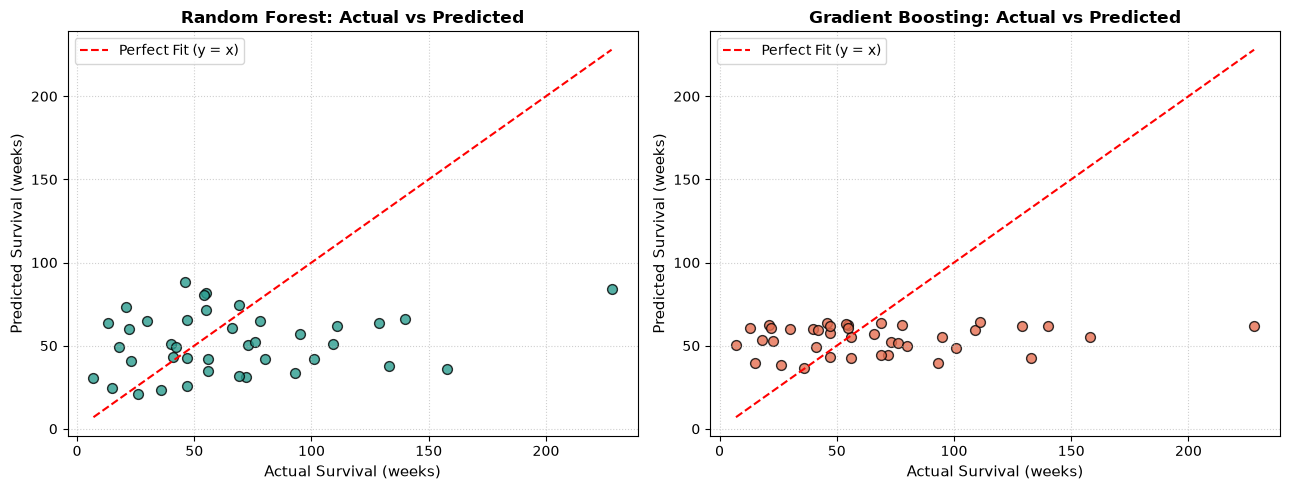

In [21]:
saved_test_df = pd.read_csv("test_dataset_holdout.csv")
print(f"Loaded holdout test cohort: {len(saved_test_df)} patients.")

X_test = saved_test_df[final_predictors]
y_test = pd.to_numeric(saved_test_df[target_col], errors="coerce")

# Predictions in log space, converted back with Duan's Smearing Factor
y_pred_rf_log = rf_pipeline.predict(X_test)
y_pred_rf = np.maximum(0.0, smearing_rf * np.exp(y_pred_rf_log) - 1.0)

y_pred_hgb_log = hgb_pipeline.predict(X_test)
y_pred_hgb = np.maximum(0.0, smearing_hgb * np.exp(y_pred_hgb_log) - 1.0)

# Check Prediction Distribution & Dynamic Spread
spread_df = pd.DataFrame({
    "Actual Test Survival": y_test.describe(),
    "Random Forest Pred": pd.Series(y_pred_rf).describe(),
    "Gradient Boosting Pred": pd.Series(y_pred_hgb).describe()
})
print("\n--- Verification of Prediction Spread (Min, Median, Mean, Max) ---")
display(spread_df.round(1))

def calc_metrics(y_true, y_pred):
    return [
        r2_score(y_true, y_pred),
        np.sqrt(mean_squared_error(y_true, y_pred)),
        mean_absolute_error(y_true, y_pred),
        spearmanr(y_true, y_pred)[0]
    ]

comparison_df = pd.DataFrame({
    "Random Forest": calc_metrics(y_test, y_pred_rf),
    "Gradient Boosting (HistGBM)": calc_metrics(y_test, y_pred_hgb)
}, index=["R² Score", "RMSE (weeks)", "MAE (weeks)", "Spearman Rank Correlation (ρ)"])

print("\nModel Benchmark on Saved Holdout Test Set:")
display(comparison_df.round(3))

# Diagnostic Plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Random Forest
axes[0].scatter(y_test, y_pred_rf, color="#2a9d8f", edgecolors="k", s=50, alpha=0.8)
lims = [min(y_test.min(), y_pred_rf.min()), max(y_test.max(), y_pred_rf.max())]
axes[0].plot(lims, lims, "r--", lw=1.5, label="Perfect Fit (y = x)")
axes[0].set_xlabel("Actual Survival (weeks)", fontsize=11)
axes[0].set_ylabel("Predicted Survival (weeks)", fontsize=11)
axes[0].set_title("Random Forest: Actual vs Predicted", fontsize=12, fontweight="bold")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

# Gradient Boosting
axes[1].scatter(y_test, y_pred_hgb, color="#e76f51", edgecolors="k", s=50, alpha=0.8)
lims_h = [min(y_test.min(), y_pred_hgb.min()), max(y_test.max(), y_pred_hgb.max())]
axes[1].plot(lims_h, lims_h, "r--", lw=1.5, label="Perfect Fit (y = x)")
axes[1].set_xlabel("Actual Survival (weeks)", fontsize=11)
axes[1].set_ylabel("Predicted Survival (weeks)", fontsize=11)
axes[1].set_title("Gradient Boosting: Actual vs Predicted", fontsize=12, fontweight="bold")
axes[1].legend()
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

## 7. Feature Importance & Biomarker Discovery

Top 15 Most Influential Features (Test Permutation Importance):


,Feature,Importance_Mean,Importance_Std
15,rad_flair_original_glcm_Contrast,0.0755,0.0159
0,age_at_t0 (years),0.0494,0.0137
14,size_t0 (cm3),0.0426,0.0064
7,dose (Gy),0.0380,0.0051
29,rad_flair_original_ngtdm_Contrast,0.0364,0.0060
22,rad_flair_original_glszm_GrayLevelNonUniformity,0.0158,0.0029
6,delay_t0_to_radiotherapy (weeks),0.0153,0.0039
19,rad_flair_original_gldm_SmallDependenceEmphasis,0.0126,0.0029
18,rad_flair_original_glcm_Id,0.0097,0.0007
16,rad_flair_original_glcm_DifferenceAverage,0.0076,0.0019


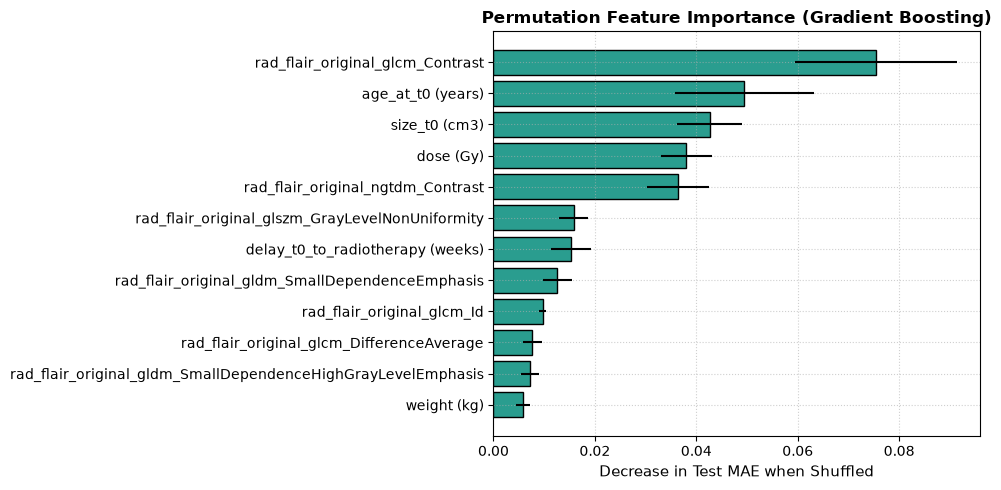

In [22]:
perm_importance = permutation_importance(
    hgb_pipeline,
    X_test,
    y_pred_hgb_log, # evaluate on log predictions to assess feature impact directly
    n_repeats=15,
    random_state=RANDOM_SEED,
    scoring="neg_mean_absolute_error"
)

importance_df = pd.DataFrame({
    "Feature": final_predictors,
    "Importance_Mean": perm_importance.importances_mean,
    "Importance_Std": perm_importance.importances_std
}).sort_values("Importance_Mean", ascending=False)

print("Top 15 Most Influential Features (Test Permutation Importance):")
display(importance_df.head(15).round(4))

top_feats = importance_df.head(12).sort_values("Importance_Mean", ascending=True)
plt.figure(figsize=(10, 5))
plt.barh(top_feats["Feature"], top_feats["Importance_Mean"], xerr=top_feats["Importance_Std"], color="#2a9d8f", edgecolor="black")
plt.title("Permutation Feature Importance (Gradient Boosting)", fontsize=12, fontweight="bold")
plt.xlabel("Decrease in Test MAE when Shuffled", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()